# 10 - Explainability with SHAP

Explain the strongest challenger (**LGBM-full**, `09_lightgbm`) with TreeSHAP and compare its explanations with the scorecard.

**Two scales**
- *Log-odds of default* (standard SHAP plots): SHAP > 0 pushes towards default (red = riskier).
- *Score points* (case studies, reason codes): `points = −factor × SHAP`, with `factor` from `08_scorecard`, so both models speak the language of the credit score. Positive points = safer. For the scorecard, the equivalent of SHAP is each feature's points minus its average points on train (centred points).

**Steps**
1. Global view: beeswarm and importance, LGBM-full vs scorecard.
2. Dependence plots of the top features.
3. Why monotone constraints matter: `EXT_SOURCE_3` in LGBM-16 vs LGBM-16-mono.
4. Case studies at cut-off 550: rejected by both, approved by both, and a disagreement. Waterfall in points and reason codes from each model.

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.explain import (
    base_score,
    center_points,
    lgbm_contributions,
    mean_abs_importance,
    numeric_view,
    pick_case,
    reason_codes,
    to_points,
)
from src.gbm import prepare_features
from src.scorecard import pd_to_score, points_frame
from src.woe import bin_frame

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

CUTOFF = 550        # approve if score >= CUTOFF (see cut-off table in 08_scorecard)
N_PLOT = 5000       # test rows used for global plots
TOP_K = 4           # reason codes per model

BLUE, ORANGE = "#2a78d6", "#eb6834"   # + points (safer) / - points (riskier)
MUTED, GRID, INK2 = "#8a8985", "#e6e5e1", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
})

## 2. Load models, scorecard and data

In [2]:
def load_bundle(name: str) -> dict:
    """Load a LightGBM bundle saved by 09_lightgbm."""
    with open(OUTPUT_DIR / f"lgbm_{name}.pkl", "rb") as f:
        return pickle.load(f)


full, lg16, lg16m = load_bundle("lgbm_full"), load_bundle("lgbm_16"), load_bundle("lgbm_16_mono")

scaling = pd.read_csv(OUTPUT_DIR / "score_scaling.csv", index_col=0).iloc[:, 0]
factor, offset, neutral = scaling["factor"], scaling["offset"], scaling["neutral_points"]
card = pd.read_csv(OUTPUT_DIR / "scorecard.csv")
with open(OUTPUT_DIR / "woe_spec_final.pkl", "rb") as f:
    woe_spec = pickle.load(f)
SC16 = card["feature"].unique().tolist()

train = pd.read_pickle(DATA_DIR / "train.pkl")
test = pd.read_pickle(DATA_DIR / "test.pkl")
pd_test = pd.read_pickle(DATA_DIR / "pd_test_all_models.pkl")
y_test = test["TARGET"]
print(f"factor = {factor:.2f}, offset = {offset:.2f} | test {len(test):,} rows")

factor = 28.85, offset = 487.12 | test 61,503 rows


## 3. Contributions on the test set

- **LGBM-full**: exact TreeSHAP (LightGBM `pred_contrib`), converted to points.
- **Scorecard**: points per feature, centred on the train average.

Both decompositions must add up exactly to each model's score.

In [3]:
X_full = prepare_features(test, full["features"], full["levels"])
contrib_full, base_full = lgbm_contributions(full["model"], X_full)
pts_full = to_points(contrib_full, factor)
base_full_score = base_score(base_full, factor, offset)

score_sc = pd_to_score(pd_test["Scorecard"], factor, offset)
score_lg = pd_to_score(pd_test["LGBM-full"], factor, offset)
assert np.allclose(base_full_score + pts_full.sum(axis=1), score_lg)

spec16 = {f: woe_spec[f] for f in SC16}
pts_sc_train = points_frame(bin_frame(train, spec16), card, neutral)
pts_sc = center_points(points_frame(bin_frame(test, spec16), card, neutral), pts_sc_train)
base_sc_score = pts_sc_train.sum(axis=1).mean()
assert np.allclose(base_sc_score + pts_sc.sum(axis=1), score_sc)

print(f"Average-applicant score: LGBM-full {base_full_score:.1f} | scorecard {base_sc_score:.1f}")

Average-applicant score: LGBM-full 568.5 | scorecard 567.0


## 4. Global view

Beeswarm of LGBM-full on 5,000 test rows (log-odds scale: right = riskier; colour = feature value, categorical features coloured by category code).

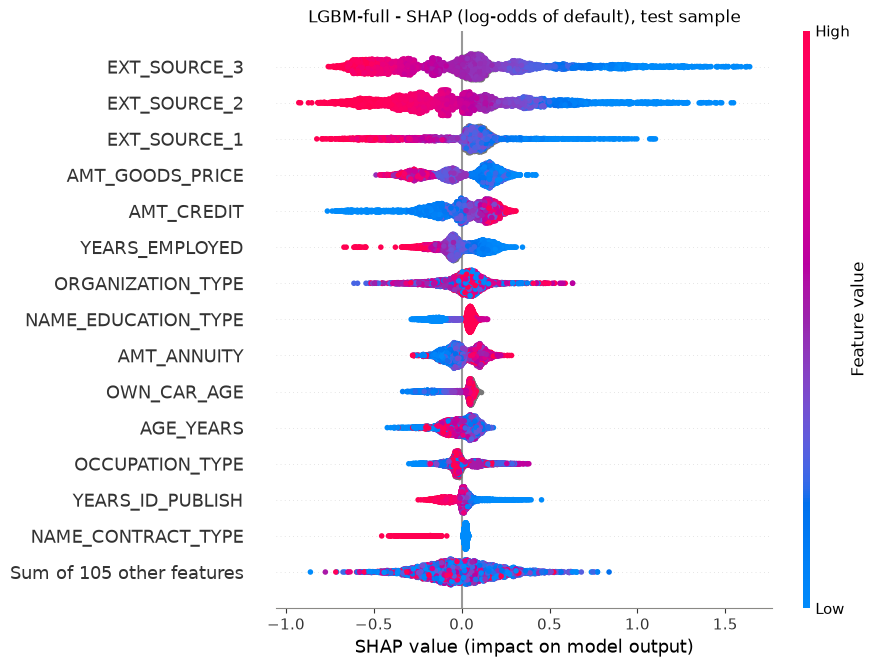

In [4]:
plot_idx = X_full.sample(N_PLOT, random_state=0).index
expl_full = shap.Explanation(
    values=contrib_full.loc[plot_idx].to_numpy(),
    base_values=np.full(len(plot_idx), base_full),
    data=numeric_view(X_full.loc[plot_idx]).to_numpy(),
    feature_names=list(X_full.columns),
)
shap.plots.beeswarm(expl_full, max_display=15, show=False)
plt.title("LGBM-full - SHAP (log-odds of default), test sample")
plt.gcf().savefig(OUTPUT_DIR / "shap_beeswarm_lgbm_full.png", dpi=150, bbox_inches="tight")
plt.show()

Global importance in points (mean |contribution|): which features move the score most, for each model.

In [5]:
importance = pd.DataFrame({
    "lgbm_full": mean_abs_importance(pts_full),
    "scorecard": mean_abs_importance(pts_sc),
}).sort_values("lgbm_full", ascending=False)
importance["in_scorecard"] = importance.index.isin(SC16)
importance["lgbm_rank"] = range(1, len(importance) + 1)

top20 = importance.head(20)
print(f"Scorecard features in LGBM-full top 20: {top20['in_scorecard'].sum()} / {len(SC16)}")
print(f"Share of LGBM-full importance from the 16 scorecard features: "
      f"{importance.loc[importance['in_scorecard'], 'lgbm_full'].sum() / importance['lgbm_full'].sum():.1%}")
top20.round(2)

Scorecard features in LGBM-full top 20: 13 / 16
Share of LGBM-full importance from the 16 scorecard features: 66.0%


,lgbm_full,scorecard,in_scorecard,lgbm_rank
EXT_SOURCE_3,10.37,11.85,True,1
EXT_SOURCE_2,9.15,9.35,True,2
EXT_SOURCE_1,4.98,4.35,True,3
AMT_GOODS_PRICE,4.93,1.79,True,4
AMT_CREDIT,4.04,NaN,False,5
YEARS_EMPLOYED,3.03,2.87,True,6
ORGANIZATION_TYPE,2.66,1.89,True,7
NAME_EDUCATION_TYPE,2.22,3.15,True,8
AMT_ANNUITY,2.21,NaN,False,9
OWN_CAR_AGE,2.20,2.07,True,10


## 5. Dependence plots (top numeric features of LGBM-full)

Each dot is one applicant: x = feature value, y = SHAP (log-odds of default). A clean monotone shape means the model's logic matches the scorecard; wiggles show where it does not.

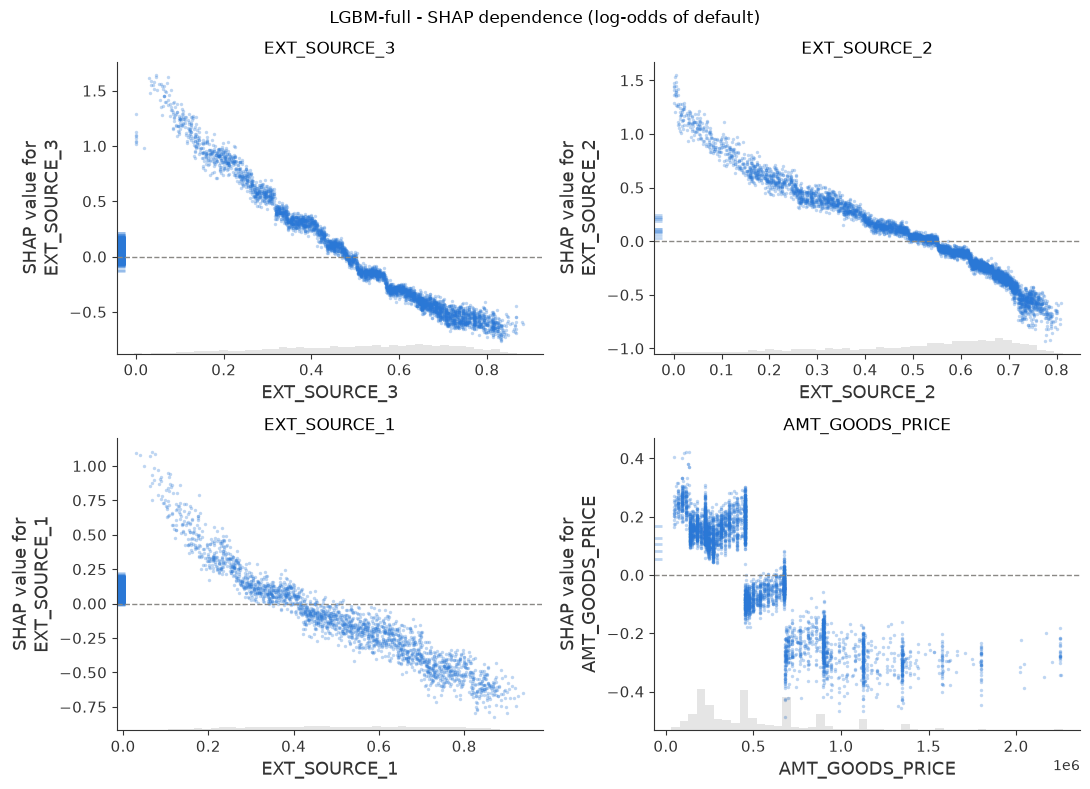

In [6]:
numeric_cols = [c for c in importance.index if not isinstance(X_full[c].dtype, pd.CategoricalDtype)]
top_numeric = numeric_cols[:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flat, top_numeric):
    shap.plots.scatter(expl_full[:, feat], ax=ax, show=False, color=BLUE, alpha=0.3, dot_size=6)
    ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(feat)
fig.suptitle("LGBM-full - SHAP dependence (log-odds of default)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "shap_dependence_lgbm_full.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Why monotone constraints matter: `EXT_SOURCE_3`

Same 16 features, with and without monotone constraints. Without them, a higher external score can *raise* the predicted risk for some applicants, which is hard to defend in a rejection letter.

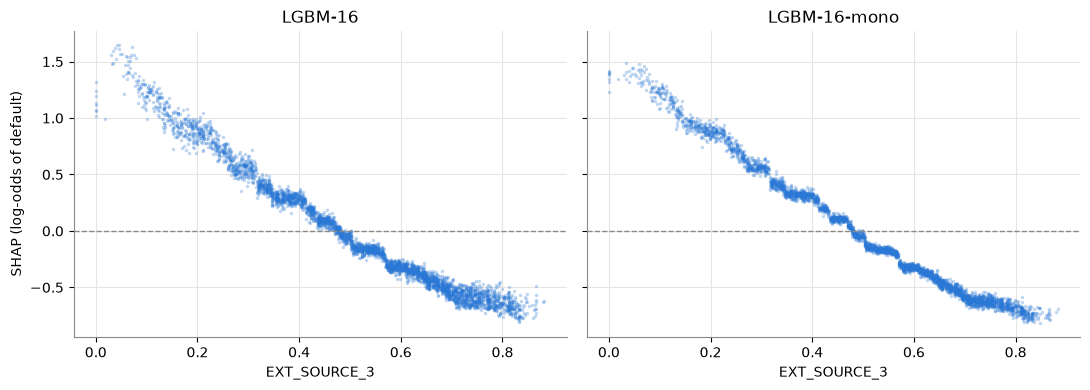

In [7]:
FEAT = "EXT_SOURCE_3"
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, bundle) in zip(axes, [("LGBM-16", lg16), ("LGBM-16-mono", lg16m)]):
    X = prepare_features(test.loc[plot_idx], bundle["features"], bundle["levels"])
    contrib, _ = lgbm_contributions(bundle["model"], X)
    ax.scatter(X[FEAT], contrib[FEAT], s=6, alpha=0.3, color=BLUE, linewidths=0)
    ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
    ax.set(title=name, xlabel=FEAT)
    ax.grid(True)
axes[0].set_ylabel("SHAP (log-odds of default)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "shap_monotone_ext_source_3.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Case studies at cut-off 550

1. **Rejected by both**: median score among applicants both models reject.
2. **Approved by both**: median score among applicants both models approve.
3. **Disagreement**: scorecard rejects, LGBM-full approves (median score gap in that group).

In [8]:
appr_sc, appr_lg = score_sc >= CUTOFF, score_lg >= CUTOFF
print(pd.crosstab(appr_sc.map({True: "SC approve", False: "SC reject"}),
                  appr_lg.map({True: "LGBM approve", False: "LGBM reject"}), normalize=True).round(3))

gap = score_lg - score_sc
masks = {
    "Rejected by both": (~appr_sc & ~appr_lg, score_sc),
    "Approved by both": (appr_sc & appr_lg, score_sc),
    "Scorecard rejects, LGBM approves": (~appr_sc & appr_lg, gap),
}
cases = {name: pick_case(s, m, s[m].median()) for name, (m, s) in masks.items()}

pd.DataFrame({
    name: {"SK_ID_CURR": test.loc[i, "SK_ID_CURR"], "score_scorecard": score_sc[i], "score_lgbm_full": score_lg[i],
           "pd_scorecard": pd_test.loc[i, "Scorecard"], "pd_lgbm_full": pd_test.loc[i, "LGBM-full"],
           "actual_default": y_test[i]}
    for name, i in cases.items()
}).T.round(3)

score       LGBM approve  LGBM reject
score                                
SC approve         0.693        0.043
SC reject          0.063        0.201


,SK_ID_CURR,score_scorecard,score_lgbm_full,pd_scorecard,pd_lgbm_full,actual_default
Rejected by both,316822.0,533.306,514.120,0.168,0.282,1.0
Approved by both,223122.0,578.215,574.844,0.041,0.046,0.0
"Scorecard rejects, LGBM approves",236298.0,545.857,561.063,0.116,0.072,0.0


In [9]:
def fmt_value(v: object) -> str:
    """Readable feature value for axis labels."""
    if pd.isna(v):
        return "missing"
    return f"{v:.3g}" if isinstance(v, (int, float, np.integer, np.floating)) else str(v)


def plot_waterfall(points: pd.Series, base: float, values: pd.Series, title: str, ax: plt.Axes, top: int = 10) -> None:
    """Waterfall in score points: base score -> top contributions -> final score."""
    order = points.abs().sort_values(ascending=False).index
    shown, rest = order[:top], order[top:]
    steps = [(f"{f} = {fmt_value(values[f])}", points[f]) for f in shown]
    if len(rest):
        steps.append((f"{len(rest)} other features", points[rest].sum()))
    path = base + np.cumsum([0.0] + [v for _, v in steps])
    lo, hi = min(path.min(), CUTOFF), max(path.max(), CUTOFF)
    pad = 0.12 * (hi - lo)
    for y, ((label, v), start) in enumerate(zip(steps, path[:-1])):
        ax.barh(y, v, left=start, color=BLUE if v >= 0 else ORANGE, height=0.7)
        end = start + v
        ax.text(end + (0.01 if v >= 0 else -0.01) * (hi - lo), y, f"{v:+.1f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yticks(range(len(steps)), [s[0] for s in steps], fontsize=8)
    ax.invert_yaxis()
    ax.axvline(base, color=MUTED, linewidth=1, linestyle="--")
    ax.axvline(CUTOFF, color=INK2, linewidth=1, linestyle=":")
    ax.set(title=f"{title}\nbase {base:.0f} -> score {path[-1]:.0f} (cut-off {CUTOFF})", xlabel="Score points")
    ax.grid(axis="x")


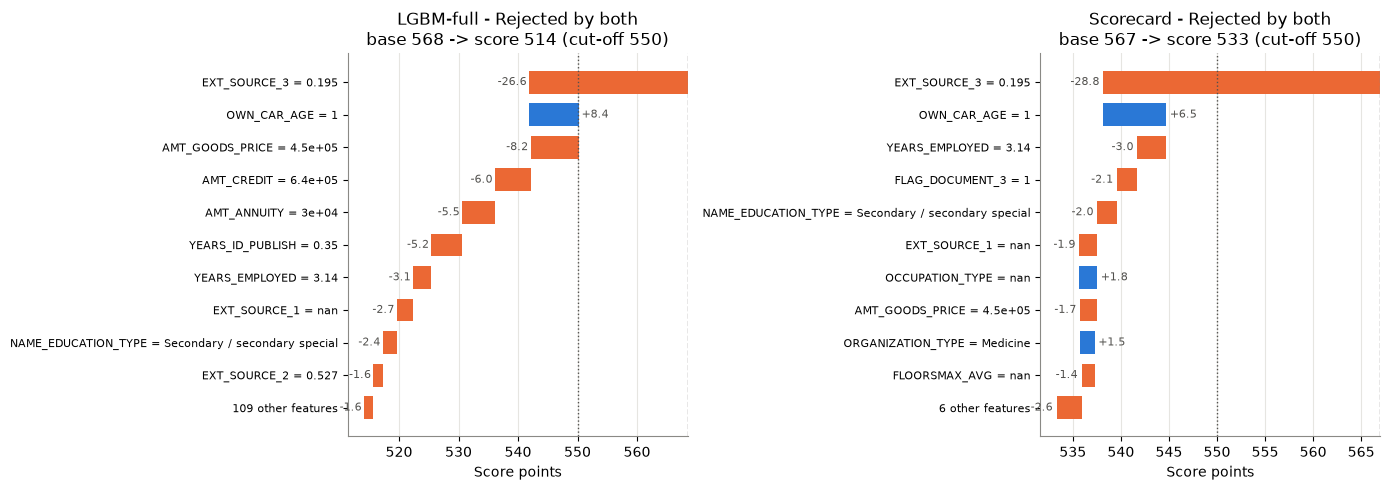

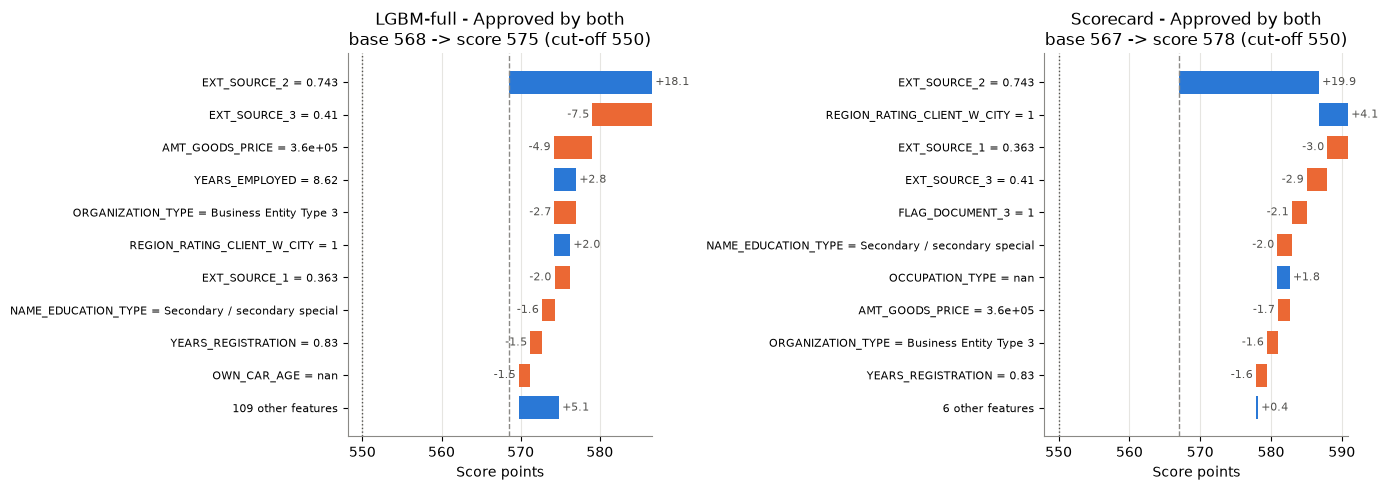

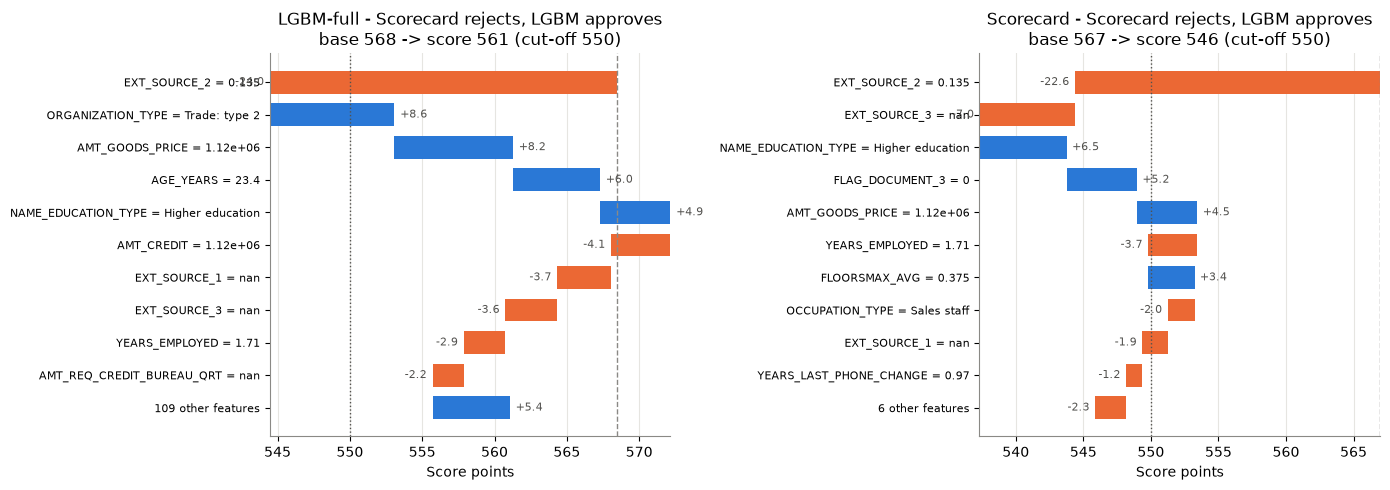

In [10]:
raw_test = test[full["features"]]
for k, (name, i) in enumerate(cases.items(), start=1):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_waterfall(pts_full.loc[i], base_full_score, raw_test.loc[i], f"LGBM-full - {name}", axes[0])
    plot_waterfall(pts_sc.loc[i], base_sc_score, test.loc[i, SC16], f"Scorecard - {name}", axes[1])
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"case_{k}_waterfall.png", dpi=150, bbox_inches="tight")
    plt.show()

### Reason codes

For a rejected applicant, the top features lowering the score (adverse action reasons); for an approved one, the top features raising it. Each model judged against its own decision.

In [11]:
def reasons(i: object, model: str) -> pd.DataFrame:
    """Top reason codes of one applicant for one model."""
    pts, approved = (pts_full, appr_lg) if model == "LGBM-full" else (pts_sc, appr_sc)
    r = reason_codes(pts.loc[i], k=TOP_K, adverse=not approved[i])
    return pd.DataFrame({
        "model": model,
        "decision": "approve" if approved[i] else "reject",
        "feature": r.index,
        "value": [test.loc[i, f] for f in r.index],
        "points": r.values.round(1),
    })


reason_table = pd.concat(
    [reasons(i, m).assign(case=name) for name, i in cases.items() for m in ["Scorecard", "LGBM-full"]],
    ignore_index=True,
).set_index(["case", "model", "decision"])
reason_table

feature  \
case                             model     decision                                
Rejected by both                 Scorecard reject                   EXT_SOURCE_3   
                                           reject                 YEARS_EMPLOYED   
                                           reject                FLAG_DOCUMENT_3   
                                           reject            NAME_EDUCATION_TYPE   
                                 LGBM-full reject                   EXT_SOURCE_3   
                                           reject                AMT_GOODS_PRICE   
                                           reject                     AMT_CREDIT   
                                           reject                    AMT_ANNUITY   
Approved by both                 Scorecard approve                  EXT_SOURCE_2   
                                           approve   REGION_RATING_CLIENT_W_CITY   
                                           approve               OCCUPATION_TYPE   
                                           approve                YEARS_EMPLOYED   
                                 LGBM-full approve                  EXT_SOURCE_2   
                                           approve                YEARS_EMPLOYED   
                                           approve   REGION_RATING_CLIENT_W_CITY   
                                           approve               OCCUPATION_TYPE   
Scorecard rejects, LGBM approves Scorecard reject                   EXT_SOURCE_2   
                                           reject                   EXT_SOURCE_3   
                                           reject                 YEARS_EMPLOYED   
                                           reject                OCCUPATION_TYPE   
                                 LGBM-full approve             ORGANIZATION_TYPE   
                                           approve               AMT_GOODS_PRICE   
                                           approve                     AGE_YEARS   
                                           approve           NAME_EDUCATION_TYPE   

                                                                             value  \
case                             model     decision                                  
Rejected by both                 Scorecard reject                         0.195198   
                                           reject                             3.14   
                                           reject                                1   
                                           reject    Secondary / secondary special   
                                 LGBM-full reject                         0.195198   
                                           reject                         450000.0   
                                           reject                         640080.0   
                                           reject                          29970.0   
Approved by both                 Scorecard approve                        0.742886   
                                           approve                             1.0   
                                           approve                             NaN   
                                           approve                            8.62   
                                 LGBM-full approve                        0.742886   
                                           approve                            8.62   
                                           approve                             1.0   
                                           approve                             NaN   
Scorecard rejects, LGBM approves Scorecard reject                         0.135162   
                                           reject                              NaN   
                                           reject                             1.71   
                                           reject                      Sales staff

### Disagreement case: where do the models differ?

Contribution of the 16 shared features under each model, plus LightGBM's extra features as one line.

In [12]:
i = cases["Scorecard rejects, LGBM approves"]
diff = pd.DataFrame({"value": test.loc[i, SC16], "scorecard": pts_sc.loc[i], "lgbm_full": pts_full.loc[i, SC16]})
diff.loc["(other LGBM features)"] = [np.nan, 0.0, pts_full.loc[i].drop(SC16).sum()]
diff["gap"] = diff["lgbm_full"] - diff["scorecard"]
diff.sort_values("gap", key=abs, ascending=False).round(2)

,value,scorecard,lgbm_full,gap
ORGANIZATION_TYPE,Trade: type 2,0.31,8.62,8.31
AMT_GOODS_PRICE,1125000.0,4.47,8.20,3.73
OCCUPATION_TYPE,Sales staff,-2.00,1.55,3.54
EXT_SOURCE_3,NaN,-7.05,-3.58,3.46
FLOORSMAX_AVG,0.375,3.44,0.17,-3.27
FLAG_DOCUMENT_3,0,5.21,2.08,-3.12
(other LGBM features),NaN,0.00,2.64,2.64
EXT_SOURCE_1,NaN,-1.88,-3.72,-1.84
NAME_EDUCATION_TYPE,Higher education,6.46,4.87,-1.59
EXT_SOURCE_2,0.135162,-22.60,-24.01,-1.41


## 8. Save artifacts

In [13]:
importance.to_csv(OUTPUT_DIR / "shap_importance.csv")
reason_table.to_csv(OUTPUT_DIR / "reason_codes_cases.csv")
print("Saved shap_importance.csv, reason_codes_cases.csv, shap_*.png, case_*_waterfall.png")

Saved shap_importance.csv, reason_codes_cases.csv, shap_*.png, case_*_waterfall.png
